In [1]:
# ─────────────────────────────────────────────────────────────────────────────
# Standard Library Imports

# ─────────────────────────────────────────────────────────────────────────────
# Third-Party Imports
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path
from typing import List

# Define Seaborn style
def set_academic_style():
    
    # Color Universal Design Palette
    color_palette = [
        "#377eb8",  # azul
        "#ff7f00",  # naranja
        "#4daf4a",  # verde
        "#f781bf",  # rosa
        "#a65628",  # marrón
        "#984ea3",  # púrpura
        "#999999",  # gris
        "#e41a1c",  # rojo
        "#dede00"   # amarillo
    ]

    # Style
    sns.set(
        style="whitegrid",
        palette=color_palette,
        context="paper",
        font_scale=1.5
    )

    # Additional Matplotlib Config
    plt.rcParams.update({
        "figure.figsize": (10, 6),
        "axes.titlesize": 18,
        "axes.labelsize": 14,
        "axes.labelweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.6,
        "grid.linestyle": "--",
        "legend.fontsize": 12,
        "legend.title_fontsize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "savefig.dpi": 300,
        "savefig.format": "pdf"
    })

set_academic_style()


# Input

In [2]:
def datasetsCreator(csv_files, calibrations):
    # Leer y procesar cada archivo
    datasets: List[pl.DataFrame] = []
    for filepath in csv_files:
        df: pl.DataFrame = pl.read_csv(filepath)
        df = df.with_columns([
            (
                (pl.col("timestamp") - pl.col("timestamp").min())
                .cast(pl.Duration("ns")) + pl.lit(0).cast(pl.Datetime("ns"))
            ).alias("timestamp"),
            pl.col("value").cast(pl.Int64)
        ])
        # Filter PTP metrics
        df_ptp = df.filter(
            pl.col("metric").str.contains("PPS") | 
            pl.col("metric").str.contains("offset")
            )

        # PTP Correspondence
        ptp_map = {
            "PPS_3_PPSAnalyzer": "TimeStick_hw_offset",
            "PPS_4_PPSAnalyzer": "Intel 710_hw_offset",
            "PPS_5_PPSAnalyzer": "Intel 810_hw_offset",
            "offset_TimeStick_PTP_Log": "TimeStick_sw_offset",
            "offset_Intel 710_PTP_Log": "Intel 710_sw_offset",
            "offset_Intel 810_PTP_Log": "Intel 810_sw_offset",
        }

        # Name Replacement
        df_ptp = df_ptp.with_columns(
            pl.col("metric").replace(ptp_map).alias("PTP_metric"),
            pl.col("value").alias("offset_ns")
        ).drop("metric", "value")

        # Hardware PTP Dataframe
        df_hw_ptp = df_ptp.filter(
            pl.col("PTP_metric").str.contains("hw")
        ).rename({
            "offset_ns": "offset_hw_ns",
            "PTP_metric":"PTP_client",
        }).with_columns(
            pl.col("PTP_client").replace(
                {
                    "TimeStick_hw_offset": "TimeStick",
                    "Intel 710_hw_offset": "Intel 710",
                    "Intel 810_hw_offset": "Intel 810",
                }
            )
        )
        
        df_hw_ptp_calibrated = df_hw_ptp.with_columns(
            pl.when(pl.col("PTP_client") == "TimeStick")
            .then(pl.col("offset_hw_ns") - calibrations[0])
            .otherwise(
                pl.when(pl.col("PTP_client") == "Intel 710")
                .then(pl.col("offset_hw_ns") - calibrations[1])
                .otherwise(
                    pl.col("offset_hw_ns") - calibrations[2]
                )    
            )
        )
        datasets.append(df_hw_ptp_calibrated)
    return datasets

def load_datasets(base_dir: str, prefix: str, durations: List[int], suffix: str, calibrations: List[int]) -> List[List[pl.DataFrame]]:
    all_datasets: List[List[pl.DataFrame]] = []
    for duration in durations:
        time_label = f"T{duration}"
        dir_path = Path(f"{base_dir}/{prefix}-{time_label}-{suffix}")
        pattern = f"{prefix}-{time_label}-{suffix}_*.csv"
        #print(pattern)
        csv_files: List[Path] = list(dir_path.glob(pattern))
        datasets: List[pl.DataFrame] = datasetsCreator(csv_files, calibrations)
        all_datasets.append(datasets)
    return all_datasets

# WE3

In [3]:
calibrations = [162, 325, -35]

we3_dataset_L5_95_SPTM = load_datasets("../output/Ly3_WE3", "Ly3_WE3_L5_95", [1440], "TM1", calibrations)[0][0]
we3_dataset_L5_95_LPTM = load_datasets("../output/Ly3_WE3", "Ly3_WE3_L5_95", [1440], "TM2", calibrations)[0][0]


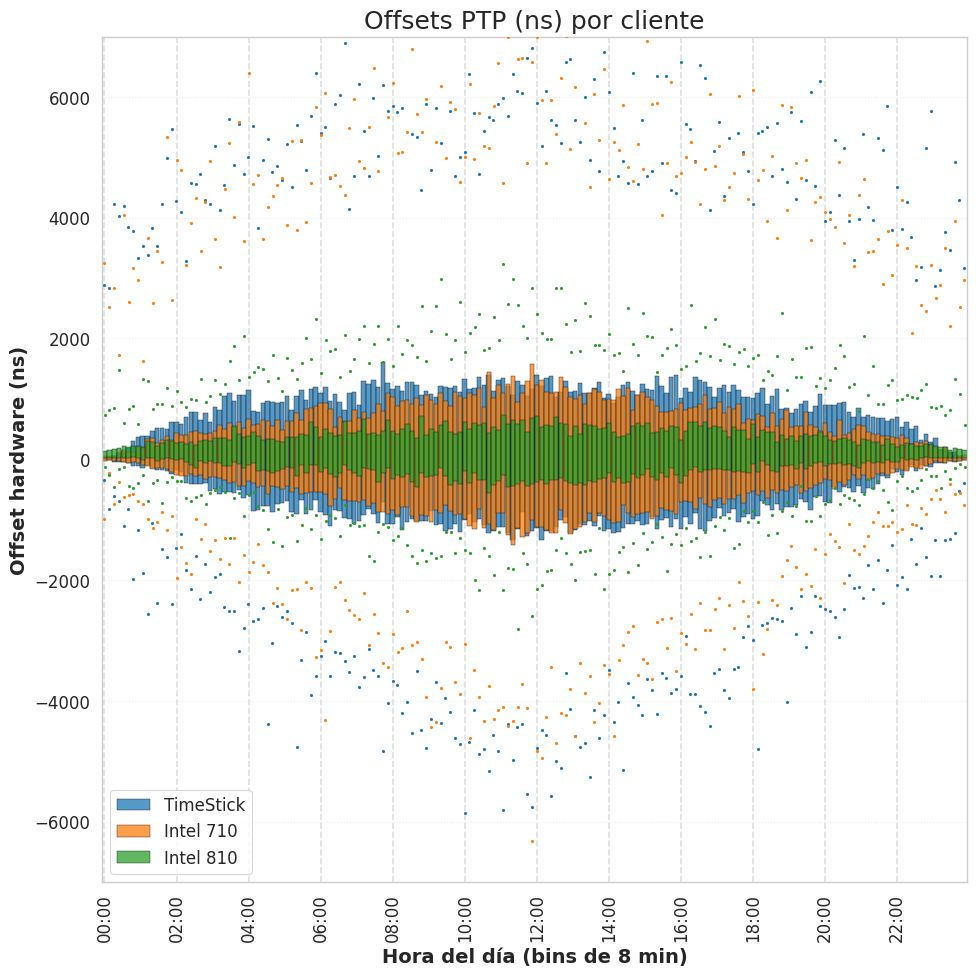

In [4]:
from typing import Dict, Tuple, List
import polars as pl
import matplotlib.pyplot as plt

def plot_boxplots_8min(
    df: pl.DataFrame
) -> None:
    """
    Genera boxplots por bins de 8 minutos para cada cliente PTP.
    - Etiquetas del eje X: cada 2 horas (HH:00).
    - Líneas verticales: cada 2 horas (coinciden con las etiquetas).
    """

    # Asegurar tipo datetime en ns
    df = df.with_columns(
        pl.col("timestamp").cast(pl.Datetime("ns"))
    )

    # Tamaño de bin: 8 min en nanosegundos
    BIN_NS: int = 8 * 60 * 1_000_000_000

    # Bin y comienzo del bin
    df = df.with_columns([
        (pl.col("timestamp").dt.epoch("ns") // BIN_NS).alias("bin_8m"),
        ((pl.col("timestamp").dt.epoch("ns") // BIN_NS) * BIN_NS)
            .cast(pl.Datetime("ns"))
            .alias("t_start"),
    ])

    # Lista ordenada de bins
    bins: pl.DataFrame = df.select(["bin_8m", "t_start"]).unique().sort("bin_8m")
    intervalos: List[int] = bins["bin_8m"].to_list()
    horas_de_intervalos: List[int] = bins["t_start"].dt.hour().to_list()
    minutos_de_intervalos: List[int] = bins["t_start"].dt.minute().to_list()
    N: int = len(intervalos)

    # --- Etiquetas cada 2 horas ---
    # Con bins de 8 minutos, t_start minute == 0 se repite cada 2 horas.
    tick_positions: List[int] = [i for i, m in enumerate(minutos_de_intervalos) if m == 0]
    tick_labels: List[str] = [f"{horas_de_intervalos[i]:02d}:00" for i in tick_positions]

    clientes: List[str] = ["TimeStick", "Intel 710", "Intel 810"]
    palette: Dict[str, str] = {
        "TimeStick": "#1f77b4",
        "Intel 710": "#ff7f0e",
        "Intel 810": "#2ca02c",
    }
    offsets: Dict[str, float] = {
        "TimeStick": -0.03,
        "Intel 710": 0.00,
        "Intel 810": 0.03,
    }

    # --- Agrupación simple ---
    groups: pl.DataFrame = (
        df.group_by(["bin_8m", "PTP_client"])
        .agg(pl.col("offset_hw_ns"))
    )

    # Convertimos a dict: (bin, cliente) -> lista de offsets
    group_dict: Dict[Tuple[int, str], List[float]] = {
        (row["bin_8m"], row["PTP_client"]): row["offset_hw_ns"]
        for row in groups.iter_rows(named=True)
    }

    plt.figure(figsize=(10, 10))

    # --- Construir datos y graficar ---
    for cliente in clientes:
        data: List[List[float]] = [
            group_dict.get((b, cliente), [None])
            for b in intervalos
        ]

        pos: List[float] = [i + offsets[cliente] for i in range(N)]

        plt.boxplot(
            data,
            positions=pos,
            widths=0.95,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(facecolor=palette[cliente], alpha=0.75, linewidth=0.35),
            whiskerprops=dict(visible=False),
            capprops=dict(visible=False),
            medianprops=dict(visible=False),
            label=cliente
        )
        
        # Marcar min/max por bin y cliente
        for i, sub in enumerate(data):
            if sub and sub != [None]:
                ymin, ymax = min(sub), max(sub)
                plt.scatter(pos[i], ymin, color=palette[cliente], s=2, zorder=3)
                plt.scatter(pos[i], ymax, color=palette[cliente], s=2, zorder=3)
        

    # --- Eje X: etiquetas y líneas cada 2h ---
    plt.xticks(tick_positions, tick_labels, rotation=90)
    for i in tick_positions:
        plt.axvline(i, color="gray", linestyle="--", alpha=0.25, zorder=0)

    # Desactivar grid en X y mantenerlo en Y si quieres
    plt.grid(axis="x", visible=False)
    plt.grid(axis="y", linestyle=":", alpha=0.4)

    plt.title("Offsets PTP (ns) por cliente")
    plt.ylabel("Offset hardware (ns)")
    plt.xlabel("Hora del día (bins de 8 min)")
    plt.xlim(-0.5, N - 0.5)
    plt.ylim(-7000, 7000)

    plt.legend()

    plt.tight_layout()
    plt.savefig(
        "Experiment3.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.05
    )

plot_boxplots_8min(we3_dataset_L5_95_LPTM)


In [5]:
calibrations = [162, 325, -35]

we3_dataset_L5_95_SPTM = load_datasets("../output/Ly3_WE3", "Ly3_WE3_L5_95", [1440], "TM1", calibrations)[0][0]
we3_dataset_L5_95_LPTM = load_datasets("../output/Ly3_WE3", "Ly3_WE3_L5_95", [1440], "TM2", calibrations)[0][0]

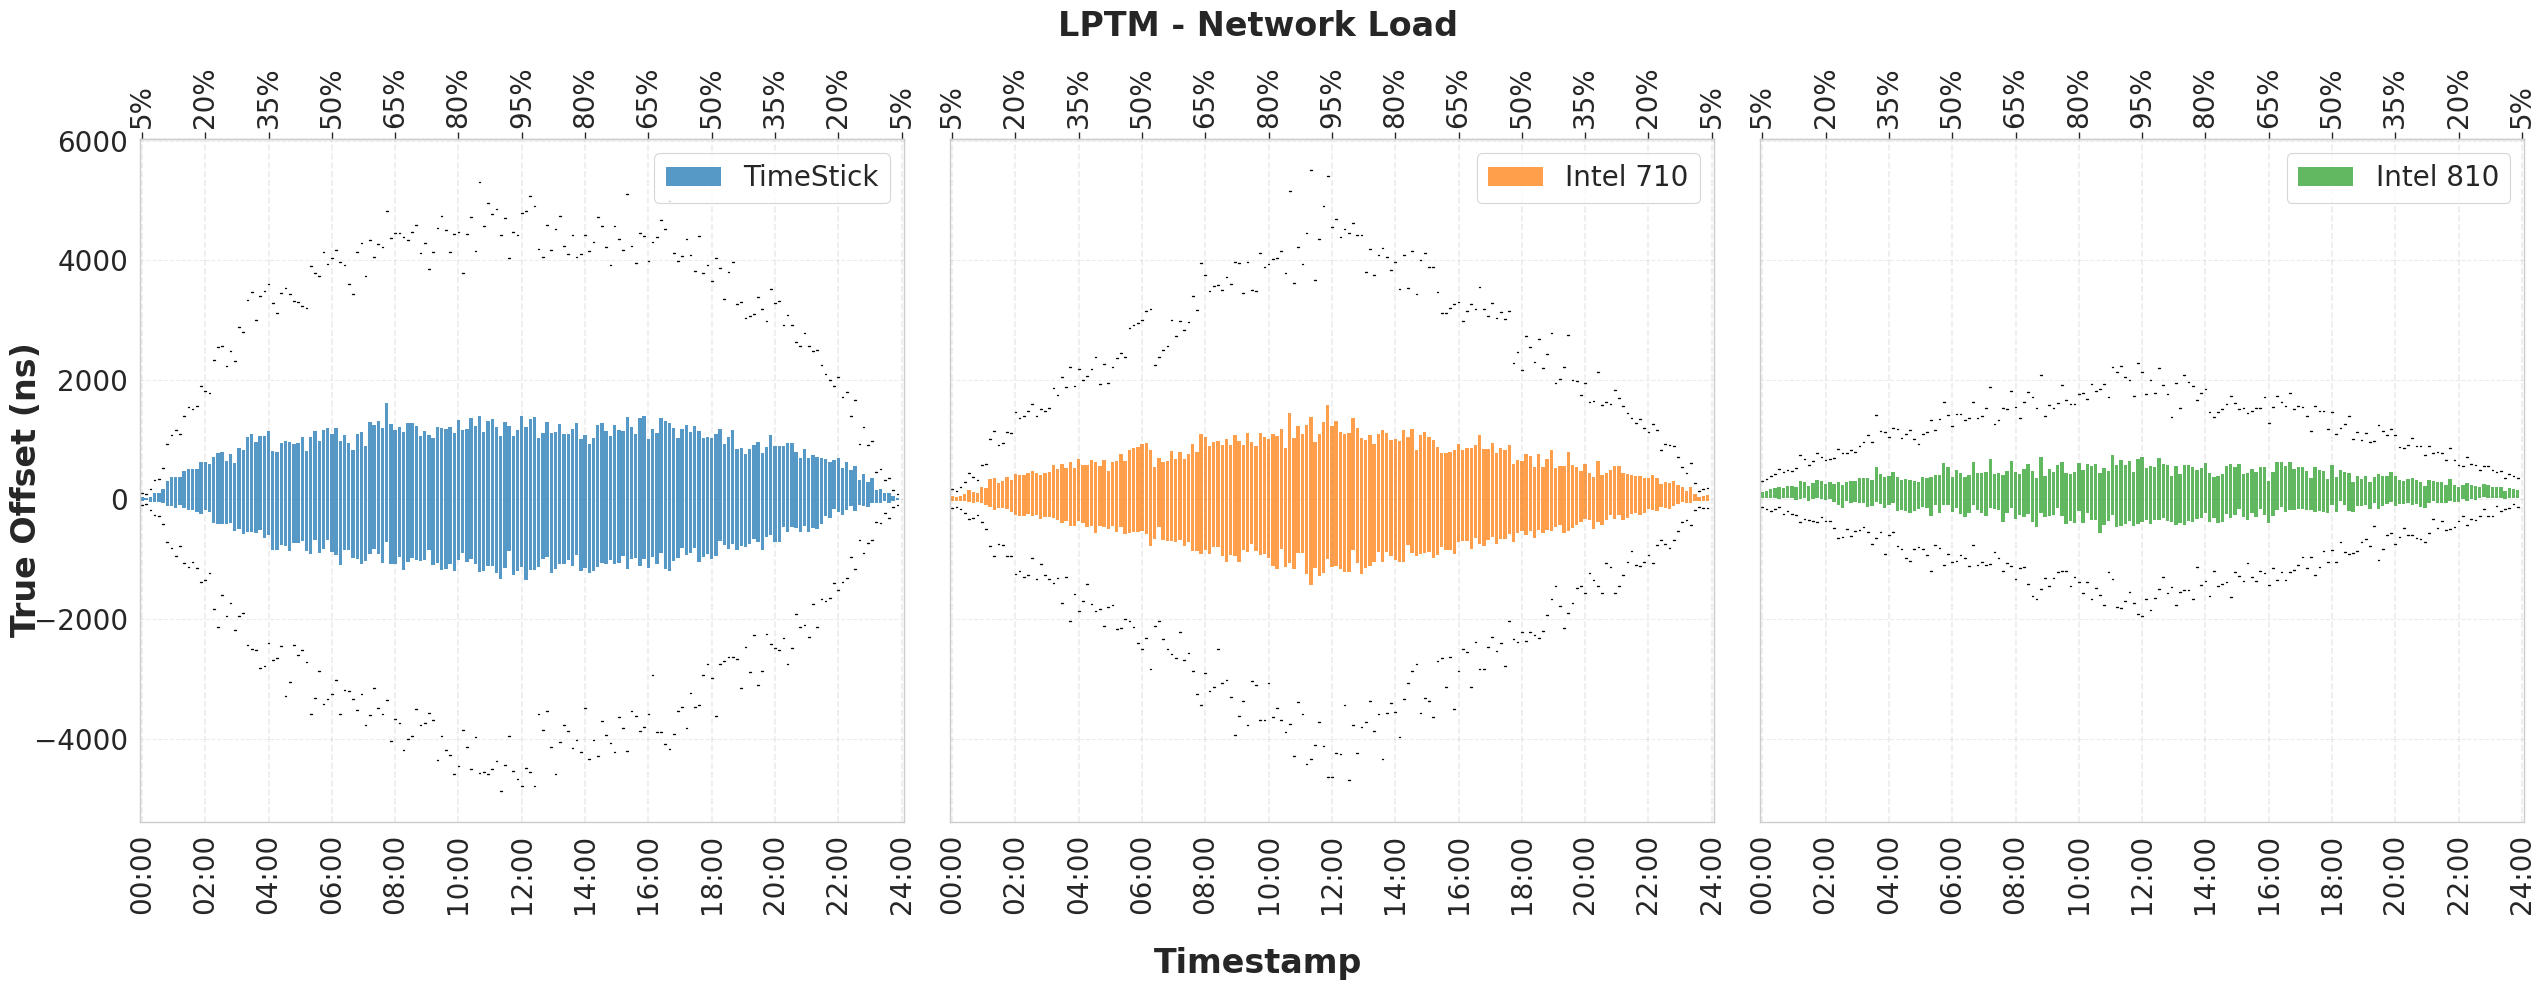

In [6]:
from typing import Dict, Tuple, List
import polars as pl
import matplotlib.pyplot as plt

def plot_boxplots_8min_horizontal(df: pl.DataFrame) -> None:
    """
    Genera 3 subplots horizontales (1 fila, 3 columnas), uno por cliente,
    compartiendo el eje Y. Añade ticks superiores con porcentajes y añade
    un tick final '24:00' aunque el último bin sea 23:52.
    """

    # Asegurar tipo datetime ns
    df = df.with_columns(
        pl.col("timestamp").cast(pl.Datetime("ns"))
    )

    # Bin de 8 min en ns
    BIN_NS: int = 8 * 60 * 1_000_000_000

    df = df.with_columns([
        (pl.col("timestamp").dt.epoch("ns") // BIN_NS).alias("bin_8m"),
        ((pl.col("timestamp").dt.epoch("ns") // BIN_NS) * BIN_NS)
            .cast(pl.Datetime("ns"))
            .alias("t_start"),
    ])

    # Lista ordenada de bins
    bins = df.select(["bin_8m", "t_start"]).unique().sort("bin_8m")
    intervalos: List[int] = bins["bin_8m"].to_list()
    horas: List[int] = bins["t_start"].dt.hour().to_list()
    minutos: List[int] = bins["t_start"].dt.minute().to_list()
    N: int = len(intervalos)

    # Ticks cada 2h (minute == 0)
    tick_positions: List[int] = [i for i, m in enumerate(minutos) if m == 0]
    tick_labels: List[str] = [f"{horas[i]:02d}:00" for i in tick_positions]

    # ---- AÑADIR TICK FINAL "24:00" ----
    final_tick_pos: int = N
    tick_positions_with_final = tick_positions + [final_tick_pos]
    tick_labels_with_final = tick_labels + ["24:00"]

    clientes: List[str] = ["TimeStick", "Intel 710", "Intel 810"]
    palette: Dict[str, str] = {
        "TimeStick": "#1f77b4",
        "Intel 710": "#ff7f0e",
        "Intel 810": "#2ca02c",
    }

    # Agrupación
    groups = (
        df.group_by(["bin_8m", "PTP_client"])
        .agg(pl.col("offset_hw_ns"))
    )

    # Dict (bin, cliente) -> lista de offsets
    group_dict: Dict[Tuple[int, str], List[float]] = {
        (row["bin_8m"], row["PTP_client"]): row["offset_hw_ns"]
        for row in groups.iter_rows(named=True)
    }

    fig, axes = plt.subplots(
        nrows=1,
        ncols=3,
        figsize=(26, 10),
        sharex=True,
        sharey=True
    )

    # ---- SECUENCIA DE PORCENTAJES (subida + bajada) ----
    etapa_base: List[int] = [
        5, 20, 35, 50, 65, 80, 95,   # Subida
        80, 65, 50, 35, 20, 5        # Bajada
    ]

    for ax, cliente in zip(axes, clientes):

        # Datos por bin
        data: List[List[float]] = [
            group_dict.get((b, cliente), [None])
            for b in intervalos
        ]

        # Boxplot
        ax.boxplot(
            data,
            positions=list(range(N)),
            widths=0.8,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(facecolor=palette[cliente], alpha=0.75, linewidth=0),
            whiskerprops=dict(linewidth=0),
            capprops=dict(linewidth=1, color="black"),
            medianprops=dict(visible=False),
            label=cliente
        )

        # ---- TICKS INFERIORES (horas + 24:00) ----
        ax.set_xticks(tick_positions_with_final, tick_labels_with_final, rotation=90, fontsize=20)

        # Líneas verticales cada 2 horas (solo sobre ticks existentes)
        for i in tick_positions_with_final:
            ax.axvline(i, color="grey", linestyle="--", alpha=0.15)

        # ---- TICKS SUPERIORES (porcentajes + final) ----

        # Crear lista de porcentajes repetida hasta cubrir los ticks inferiores
        etapas: List[int] = []
        while len(etapas) < len(tick_positions_with_final) - 1:
            etapas.extend(etapa_base)

        # Ajustar número
        etapas = etapas[:len(tick_positions_with_final) - 1]

        # Etapa final correspondiente a "24:00"
        pct_final = etapa_base[(len(etapas)) % len(etapa_base)]
        etapas_with_final = etapas + [pct_final]

        # Eje superior
        ax_top = ax.secondary_xaxis("top")
        ax_top.set_xticks(tick_positions_with_final)
        ax_top.set_xticklabels([f"{e}%" for e in etapas_with_final], rotation=90, fontsize=20)
        ax.tick_params(axis='y', labelsize=20)
        ax.grid(axis="both")
        ax.grid(axis="y", linestyle="--", color="grey", alpha=0.15)

        # ---- AJUSTAR X PARA VER 24:00 ----
        ax.set_xlim(-0.5, N + 0.5)

        #ax.set_title(cliente)
        ax.legend(loc="upper right", fontsize=20)

    # Ejes globales
    fig.supylabel("True Offset (ns)", fontsize=24, fontweight='bold')
    fig.supxlabel("Timestamp", fontsize=24, fontweight='bold')
    fig.suptitle("LPTM - Network Load", fontsize=24, fontweight='bold')

    plt.tight_layout()
    plt.savefig(
        "Experiment3_horizontal.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.05
    )
plot_boxplots_8min_horizontal(we3_dataset_L5_95_LPTM)

In [7]:
calibrations = [162, 325, -35]

we3_dataset_L5_95_LPTM = load_datasets("../output/Ly3_WE3", "Ly3_WE3_L5_95", [900], "TM2", calibrations)[0][0]

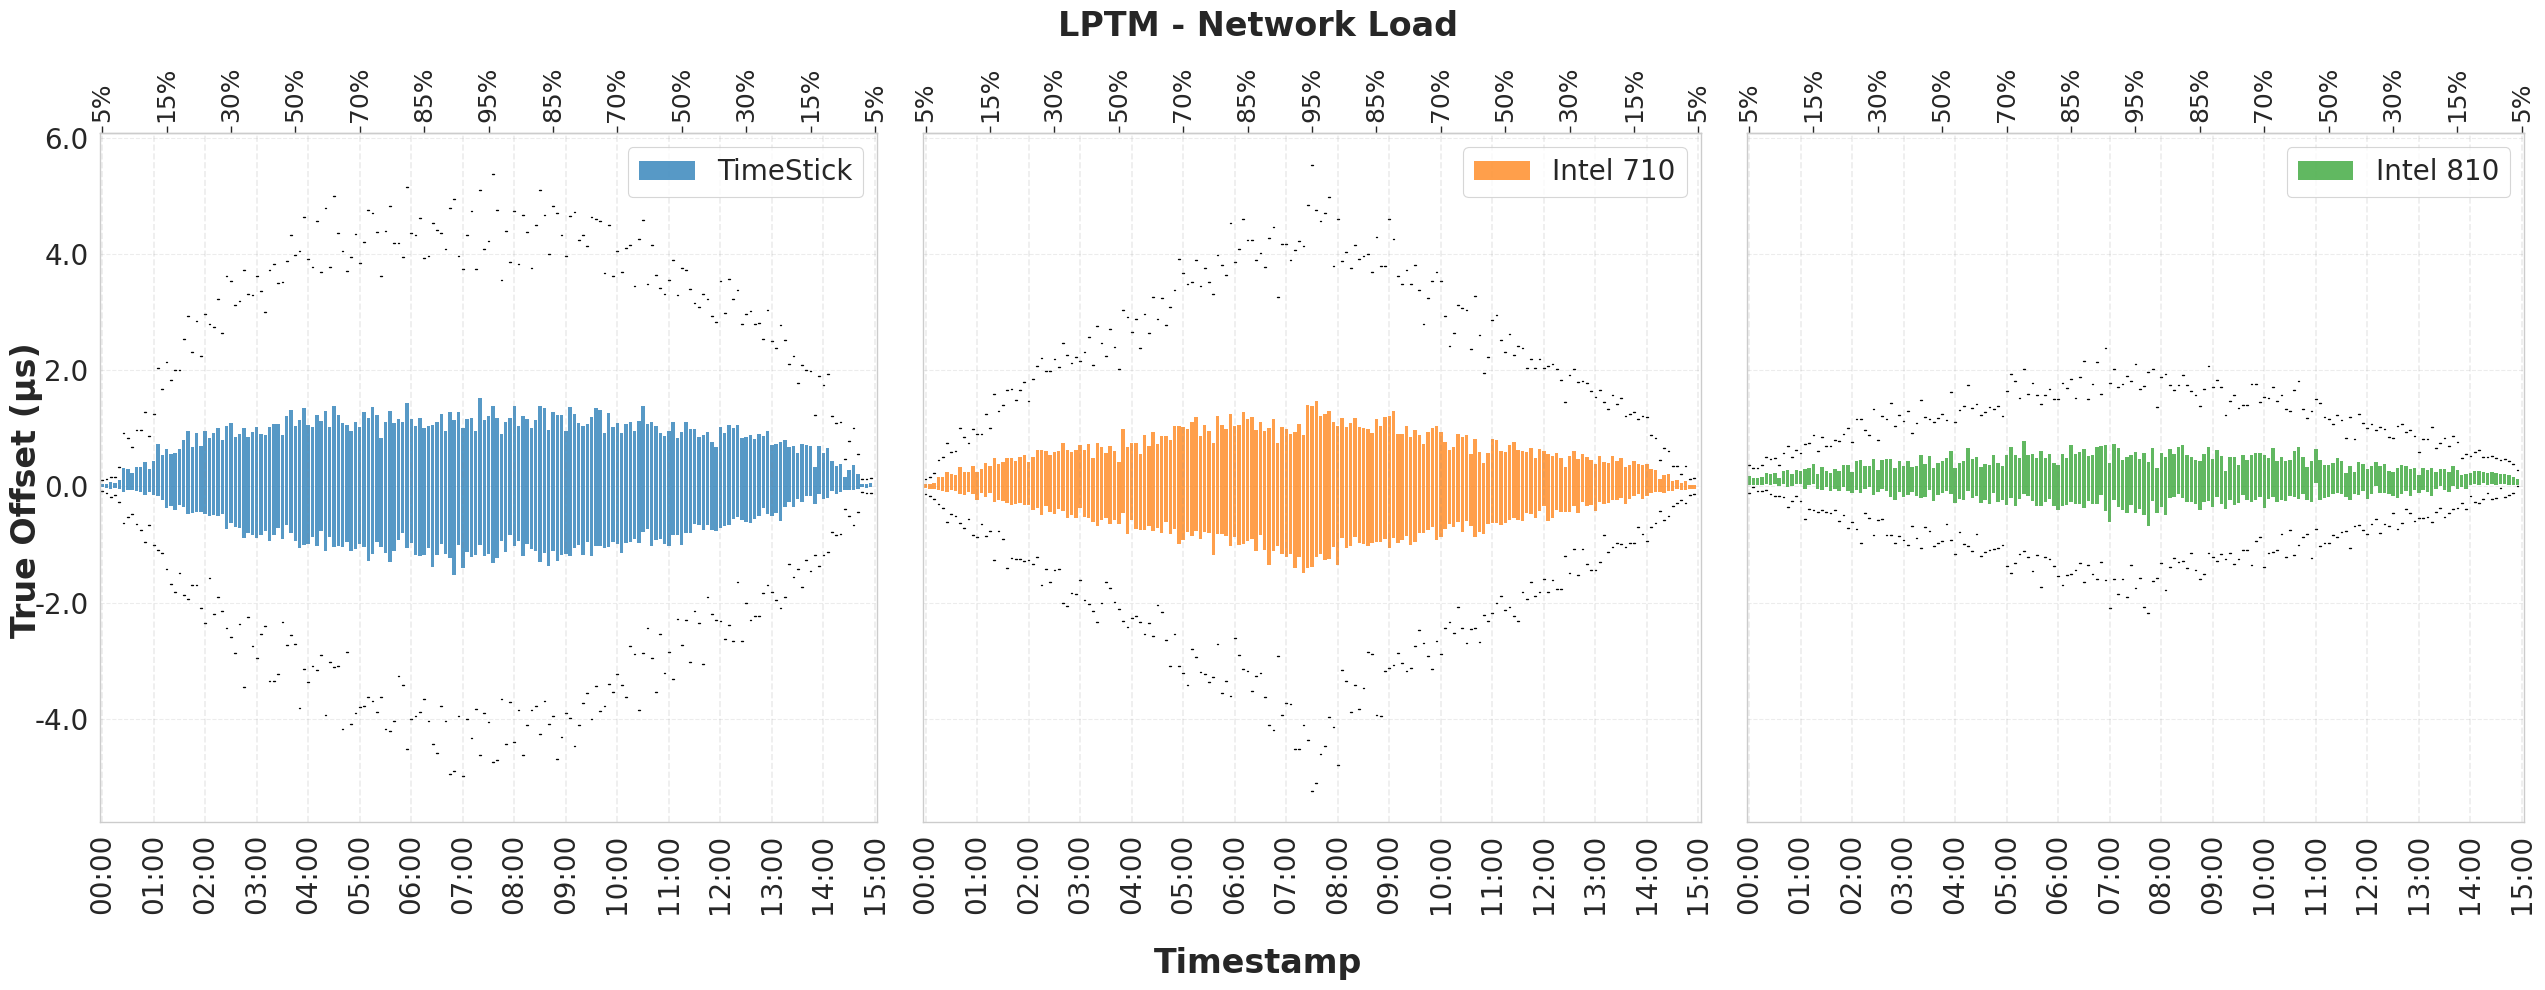

In [8]:
from typing import Dict, Tuple, List
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


def plot_boxplots_5min_horizontal(df: pl.DataFrame) -> None:
    """
    Genera 3 subplots horizontales (1 fila, 3 columnas), uno por cliente,
    compartiendo el eje Y. Añade ticks superiores con porcentajes y añade
    un tick final '15:00' para un total de 15h en bins de 5 minutos.
    """

    # Asegurar tipo datetime ns
    df = df.with_columns(
        pl.col("timestamp").cast(pl.Datetime("ns"))
    )

    # Bin de 5 min en ns
    BIN_NS: int = 5 * 60 * 1_000_000_000

    df = df.with_columns([
        (pl.col("timestamp").dt.epoch("ns") // BIN_NS).alias("bin_5m"),
        ((pl.col("timestamp").dt.epoch("ns") // BIN_NS) * BIN_NS)
            .cast(pl.Datetime("ns"))
            .alias("t_start"),
    ])

    # Lista ordenada de bins
    bins = df.select(["bin_5m", "t_start"]).unique().sort("bin_5m")
    intervalos: List[int] = bins["bin_5m"].to_list()
    horas: List[int] = bins["t_start"].dt.hour().to_list()
    minutos: List[int] = bins["t_start"].dt.minute().to_list()
    N: int = len(intervalos)

    # Ticks cada hora (minute == 0)
    tick_positions: List[int] = [i for i, m in enumerate(minutos) if m == 0]
    tick_labels: List[str] = [f"{horas[i]:02d}:00" for i in tick_positions]

    # ---- AÑADIR TICK FINAL "15:00" ----
    final_tick_pos: int = N
    tick_positions_with_final = tick_positions + [final_tick_pos]
    tick_labels_with_final = tick_labels + ["15:00"]

    clientes: List[str] = ["TimeStick", "Intel 710", "Intel 810"]
    palette: Dict[str, str] = {
        "TimeStick": "#1f77b4",
        "Intel 710": "#ff7f0e",
        "Intel 810": "#2ca02c",
    }

    # Agrupación
    groups = (
        df.group_by(["bin_5m", "PTP_client"])
        .agg(pl.col("offset_hw_ns"))
    )

    # Dict (bin, cliente) -> lista de offsets
    group_dict: Dict[Tuple[int, str], List[float]] = {
        (row["bin_5m"], row["PTP_client"]): row["offset_hw_ns"]
        for row in groups.iter_rows(named=True)
    }

    fig, axes = plt.subplots(
        nrows=1,
        ncols=3,
        figsize=(26, 10),
        sharex=True,
        sharey=True
    )

    # ---- SECUENCIA DE PORCENTAJES (subida + bajada) ----
    etapa_base: List[int] = [
        5, 20, 35, 50, 65, 80, 95,   # Subida
        80, 65, 50, 35, 20, 5        # Bajada
    ]

    for ax, cliente in zip(axes, clientes):

        # Datos por bin
        data: List[List[float]] = [
            group_dict.get((b, cliente), [None])
            for b in intervalos
        ]

        # Boxplot
        ax.boxplot(
            data,
            positions=list(range(N)),
            widths=0.8,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(facecolor=palette[cliente], alpha=0.75, linewidth=0),
            whiskerprops=dict(linewidth=0),
            capprops=dict(linewidth=1, color="black"),
            medianprops=dict(visible=False),
            label=cliente
        )

        # ---- TICKS INFERIORES (horas + 15:00) ----
        ax.set_xticks(tick_positions_with_final, tick_labels_with_final, rotation=90, fontsize=20)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y/1000}"))

        # Líneas verticales en cada tick
        for i in tick_positions_with_final:
            ax.axvline(i, color="grey", linestyle="--", alpha=0.15)



        # ---- TICKS SUPERIORES INDEPENDIENTES (subida y bajada 5 -> 95 -> 5) ----

        num_ticks_superior = 17  # por ejemplo; puedes elegir 9, 13, 17...

        # Posiciones en X para estos ticks (independientes de los horarios)
        pos_superior = list(
            np.linspace(0, N, num_ticks_superior)
        )


        porcentajes = [5, 15, 30, 50, 70, 85, 95, 85, 70, 50, 30, 15, 5]
        num_ticks_superior = len(porcentajes)
        pos_superior = np.linspace(0, N, num_ticks_superior)

        ax_top = ax.secondary_xaxis("top")
        ax_top.set_xticks(pos_superior)
        ax_top.set_xticklabels([f"{p}%" for p in porcentajes],
                            rotation=90, fontsize=18)




        ax.tick_params(axis='y', labelsize=20)
        ax.grid(axis="both")
        ax.grid(axis="y", linestyle="--", color="grey", alpha=0.15)

        # ---- AJUSTAR X PARA VER 15:00 ----
        ax.set_xlim(-0.5, N + 0.5)

        ax.legend(loc="upper right", fontsize=20)

    # Ejes globales
    fig.supylabel("True Offset (µs)", fontsize=24, fontweight='bold')
    fig.supxlabel("Timestamp", fontsize=24, fontweight='bold')
    fig.suptitle("LPTM - Network Load", fontsize=24, fontweight='bold')

    plt.tight_layout()
    plt.savefig(
        "Experiment3_horizontal.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.05
    )

# Ejemplo de llamada (ajusta el nombre de tu DataFrame si es distinto)
plot_boxplots_5min_horizontal(we3_dataset_L5_95_LPTM)